# Device-aware conjugate-gradient refinement

**Question:** Do a few conjugate-gradient steps through the device model, taken from a weighted Gerchberg-Saxton start, make the traps of an SLM with crosstalk uniform, and is their gain owed to the device model or to the loss that Schroff et al. (2023) already published?

- **Level:** 4, Proposed methods
- **Prerequisites:** notebooks 02 and 03 of this topic and notebook 01 of topic 01
- **Reading time:** about 60 minutes

## Objectives

Every method of the notebooks so far computes a hologram for an ideal SLM and trusts the result. A real SLM quantizes the phase, blurs it between neighbouring pixels (the crosstalk of the liquid crystal), has a fill factor below 1 and flickers. The standard answer is a camera in the loop, which corrects the traps after the fact. The device-aware conjugate-gradient refinement of the product asks a different question: start from a weighted Gerchberg-Saxton hologram, then run conjugate-gradient steps on a loss computed through the device model, so that the hologram is computed for the device. You will first see how wrong an ideal-model method is about its own result on the device of case C08, then run the strongest baselines the literature offers, phase-fixed weighted Gerchberg-Saxton and conjugate gradient through the crosstalk operator, and then the refinement itself, two seeds and then eight. Two variants test what its gain is owed to: the multiplicative weight update of the weighted loop, which the refinement no longer applies by default, and the normalized-error loss of Schroff et al., the closest published method. The last measurement finds where the advantage lives and where it costs.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import device_of, setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import Device, device_focal_field
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import ring
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b1_device_wgs
from pipeline.model.holo.methods.optim import m13_crosstalk_cg

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def on_device(phi, setup, traps, device):
    """Efficiency, uniformity and spread (percent) of a hologram as the device shows it, mean of four flicker draws."""
    rows = []
    for draw in range(4):
        field = device_focal_field(phi, setup, device, Rng(draw))
        i = metrics.trap_intensities(forward.trap_fields_from_fft(field, setup, traps))
        rows.append((metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)))
    return np.mean(rows, axis=0)

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence; the crosstalk parameters are those fitted by Schroff et al. 2023 (https://doi.org/10.1038/s41598-023-30296-6).
- File read: `data/examples/cases.json`, case C08: 64 traps on a 128 by 128 pixel SLM with 4 phase bits, crosstalk of fitted width 1.24 and exponent 1.8, a fill factor of 0.85 and a flicker of 0.05 rad, and two seeds counted up from the case seed.

In [2]:
# case C08: 64 traps on a 128 x 128 pixel SLM with 4 bits, pixel crosstalk, a fill factor of 0.85 and a little flicker
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C08_device_limited"]
setup = setup_of(rec)
device = device_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(rec["budget"]["iterations"])
seeds = [rec["seed"], rec["seed"] + 1]
print(f"{len(traps)} traps, {setup.n_pix} x {setup.n_pix} pixels, {device.bit_depth} bits,")
print(f"crosstalk (sigma, q): {device.crosstalk}")
print(f"fill factor {device.fill_factor}, flicker {device.flicker_rad} rad")

64 traps, 128 x 128 pixels, 4 bits,
crosstalk (sigma, q): (1.24, 1.8)
fill factor 0.85, flicker 0.05 rad


## Method

The device model of the product acts on the displayed phase in four steps: quantization to $2^b$ levels, a response curve, flicker noise, and the crosstalk, a circular convolution of the upsampled phase with a kernel whose transfer function is $\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]$, followed by the pixel aperture (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). A hologram is judged by the focal field of that displayed phase. The methods of the earlier notebooks do not know the device: phase-fixed weighted Gerchberg-Saxton (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) iterates the ideal model and stops when it is uniform on the ideal model. The metrics are those of topic 01, computed on the device and averaged over four draws of the flicker, because the flicker is random and a hologram must be good on the average device.

The device model and the loss that the refinement minimizes are written here in display form, from the product's design record of the method. The SLM displays not the phase $\phi$ that the method computes but $\phi^{\text{disp}}=K * \big(Q_b(\phi)+\xi\big)$: the phase is rounded to the nearest of $L=2^b$ levels by the quantizer $Q_b$, a random flicker $\xi\sim\mathcal N(0,\sigma_f^2)$ is added, and the result is blurred by the crosstalk kernel $K$ of the liquid crystal, whose transfer function over the spatial frequencies $(k_x,k_y)$ is

$$\widehat K(k_x,k_y)=\exp\!\Big[-\frac{|k_x|^{q}+|k_y|^{q}}{\sigma^{q}}\Big],$$

with $\sigma$ the width, fitted by Schroff et al. at $1.24\ \mathrm{px}^{-1}$ with $q=1.80$ (so a smaller $\sigma$ is a stronger blur), and $q$ the sharpness of the roll-off (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). The source gives $\sigma$ in inverse pixels and does not define the unit of the frequency further; DinHot reads the frequency in cycles per SLM pixel, so that the grid spans plus and minus one half, and every statement about the crosstalk in this notebook is relative to this device model and not to a measured instrument. The field at the traps is then $V=\mathrm{Op}(\phi)$, the Fourier transform of the displayed phase times the pixel envelope $\eta$ of topic 01. The loss that the refinement reduces with its conjugate-gradient steps is the relative squared error of the trap intensities to the targets,

$$L(\phi)=\frac{\sum_m\big(|V_m(\phi)|^2-T_m\big)^2}{\sum_m T_m^2},\qquad T_m=\eta_0\,\frac{(w_m a_m)^2}{\sum_k (w_k a_k)^2},\qquad \eta_0=\sum_m|V_m|^2,$$

where $a_m$ are the design amplitudes of the traps and $\eta_0$ is the power that the traps currently hold, so the loss asks for a redistribution among the traps and not for more total power. The $w_m$ are the weights of weighted Gerchberg-Saxton. By default the refinement keeps every $w_m=1$, so the steps fit the current efficiency with equal targets; with the option `weights=True` it first applies, before every outer iteration, the multiplicative update $w_m\leftarrow w_m\langle r\rangle/r_m$ with $r_m=|V_m|/a_m$ read on the device field and not on the ideal one, which is the form the product had until 0.02.003. The closest published loss is the normalized-error loss of Schroff et al. (2023, Eq. 3),

$$C(\phi)=s\sum_m\big(\tilde T_m-\tilde I_m\big)^2,\qquad \tilde I_m=\frac{I_m}{\sum_k I_k},\quad \tilde T_m=\frac{T_m}{\sum_k T_k},\qquad I_m=|V_m|^2,$$

with $s$ a steepness that only rescales $C$ (the product's default makes $C$ the relative squared error, so that the two losses have the same scale). The option `loss="normalized-error"` runs it through the same device model, warm start, optimizer and best-iterate safeguard as the other loss, so that the two differ in nothing else. It is invariant to the total power, so it does not hold the efficiency up by itself: the safeguard does. The gradient of either loss goes through $Q_b$ with the straight-through estimator (the quantizer is treated as the identity in the backward pass) and through $K$ by the adjoint convolution. The claims are tested by ratios of measured spreads, with the notation of the earlier notebooks, $\rho=\sigma_{\text{phase-fixed weighted GS}}/\sigma_{\text{refinement}}$, both read on the device and averaged over four flicker draws; $\rho>1$ means the refinement is more uniform.

The first cell runs weighted Gerchberg-Saxton and phase-fixed weighted Gerchberg-Saxton for the 30 iterations of the case and prints two readings of the same hologram: the spread that the method sees on the ideal model, which is the last entry of its history, and the spread that the device shows.

In [3]:
# the ideal model against the device: weighted GS and phase-fixed WGS judge themselves on the ideal model
ideal_runs = {}
for name, method in (("Weighted GS", m06_gsw), ("Phase-fixed weighted GS", m07_phase_fixed_wgs)):
    ideal_runs[name] = method.run(setup, target, budget=budget, rng=Rng(seeds[0]))
    last = ideal_runs[name].history[-1]
    shown = on_device(ideal_runs[name].phi, setup, traps, device)
    print(f"{name}: own judgement on the ideal model: sigma = {last['rel_std']:.3f} %, e = {last['efficiency']:.4f}")
    print(f"     on the device: sigma = {shown[2]:.3f} %, e = {shown[0]:.4f}")

Weighted GS: own judgement on the ideal model: sigma = 1.262 %, e = 0.8018
     on the device: sigma = 14.424 %, e = 0.6812
Phase-fixed weighted GS: own judgement on the ideal model: sigma = 0.005 %, e = 0.7958
     on the device: sigma = 13.349 %, e = 0.6761


A natural reply is that the method has not iterated enough. The cell runs phase-fixed weighted GS for 100 iterations and reads it on the device next to the 30 iteration hologram.

In [4]:
# more iterations of the ideal-model method do not help: 100 iterations of phase-fixed WGS, read on the device
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(seeds[0]))
for label, res in (("30", ideal_runs["Phase-fixed weighted GS"]), ("100", long_run)):
    shown = on_device(res.phi, setup, traps, device)
    print(f"Phase-fixed weighted GS {label:>3s} iterations: on the device: sigma = {shown[2]:.3f} %")
    print(f"     u = {shown[1]:.4f}, e = {shown[0]:.4f}")

Phase-fixed weighted GS  30 iterations: on the device: sigma = 13.349 %
     u = 0.6922, e = 0.6761
Phase-fixed weighted GS 100 iterations: on the device: sigma = 13.349 %
     u = 0.6922, e = 0.6761


## Comparison

Two lines of work answer the gap. The first is camera feedback, which corrects the traps after the hologram is made (Nogrette et al. 2014, https://arxiv.org/abs/1402.5329, bring a 19 percent rms spread to 1.4 percent in 20 iterations) and which the product emulates in notebooks of the later topics. The second puts the crosstalk model inside the optimization: Schroff et al. (2023) use it with conjugate gradient on shaped potentials, and the product's device-aware CG is that method for the traps of this case, with the gradient through the adjoint of the crosstalk operator in closed form. It is the strongest baseline for a device with crosstalk, since it optimizes the device-aware intensity directly, at the price of many iterations; the strongest baseline for the ideal model is phase-fixed weighted Gerchberg-Saxton. The cell runs device-aware CG on the device and prints the spread, the uniformity and the efficiency on the device.

Device-aware refinement does not start cold: it first runs 12 iterations of ideal-model weighted Gerchberg-Saxton from the random superposition of its seed, and then 4 outer iterations of 3 conjugate-gradient steps. A fair test of the strongest baseline gives device-aware CG the same start and the same number of conjugate-gradient steps: the cell computes that start with weighted GS (12 iterations, the same seed, so the same phase device-aware refinement starts from), runs device-aware CG for 12 iterations from it with the device of the case, and reads the result on the device. It also runs device-aware CG for 12 iterations from its own random start, to show what the start is worth to the conjugate gradient. The cell also runs device-aware CG for 40 iterations from the same start, to see whether more iterations would lower its spread, and repeats the 12-iteration run from the start of the second seed, so that the comparison with device-aware refinement rests on two seeds. The equal budget is the comparison this notebook makes.

In [5]:
# the other way to use the device model: conjugate gradient through the crosstalk operator, 12 iterations,
# from device-aware refinement's own start (12 iterations of weighted GS, same seed) and, for contrast, from its own
# random
# start
warm_starts = [m06_gsw.run(setup, target, budget=Budget(12), rng=Rng(s)).phi for s in seeds]
cg_runs = [
    m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(s), init=w)
    for s, w in zip(seeds, warm_starts)
]
cg_all = np.array([on_device(r.phi, setup, traps, device) for r in cg_runs])
cg_numbers = cg_all[0]
cold_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]))
cg_cold = on_device(cold_run.phi, setup, traps, device)
for label, row in (("from device-aware refinement's start", cg_numbers), ("from a random start", cg_cold)):
    print(f"Device-aware CG 12 iterations {label}: on the device: sigma = {row[2]:.3f} %, u = {row[1]:.4f}, e = "
          f"{row[0]:.4f}")
row = cg_all[1]
print(f"Device-aware CG 12 iterations from device-aware refinement's start, second seed: sigma = {row[2]:.3f} %, u = "
      f"{row[1]:.4f}, e = {row[0]:.4f}")
# do more iterations lower device-aware CG's spread? 40 iterations from the same start of the first seed
long_cg = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(40), rng=Rng(seeds[0]), init=warm_starts[0])
long_row = on_device(long_cg.phi, setup, traps, device)
print(f"Device-aware CG 40 iterations from device-aware refinement's start: sigma = {long_row[2]:.3f} %, u = "
      f"{long_row[1]:.4f}, e = {long_row[0]:.4f}")


Device-aware CG 12 iterations from device-aware refinement's start: on the device: sigma = 8.349 %, u = 0.8211, e = 0.6712
Device-aware CG 12 iterations from a random start: on the device: sigma = 57.314 %, u = 0.0054, e = 0.2001
Device-aware CG 12 iterations from device-aware refinement's start, second seed: sigma = 7.743 %, u = 0.8252, e = 0.6768
Device-aware CG 40 iterations from device-aware refinement's start: sigma = 8.508 %, u = 0.8202, e = 0.6715


## Evidence

The claim of the device-aware conjugate-gradient refinement: after a weighted Gerchberg-Saxton start, a few conjugate-gradient steps on the intensity loss, through the straight-through quantizer and the crosstalk operator, make the traps more uniform on the device than any ideal-model method can, and the gain comes from the device model in the loop and from the conjugate-gradient steps, not from the weight update of the weighted loop (Di Leonardo et al. 2007, Eq. 18) and not from the particular loss. The gap it fills is that the crosstalk model had been used with conjugate gradient on shaped potentials (Schroff et al. 2023) and inside a weighted loop that replaces amplitudes only (Persson et al. 2012, https://doi.org/10.1364/OE.20.022334), but not with a conjugate-gradient phase update after a weighted start for trap arrays. The component is `b1_device_wgs` in the code (the module keeps the identifier of the method from when it was a weighted loop). The refinement returns its best iterate and not its last: among the iterates that keep at least 0.9 of the warm start's efficiency, the one whose spread on its own device model is lowest, the warm start included. The rule exists because, with the weight update on, one seed in two ran away on a benchmark lattice (the weights spread to a ratio of about 1000 and the efficiency fell from 0.50 to 0.03, the module's record of 2026-10-30), and a run that converges returns its last iterate or one close to it, which the printed iterate of each run below shows. The tests that follow are the ones that can refute the claim: two seeds, then eight, against phase-fixed weighted Gerchberg-Saxton; one seed against the conjugate gradient with the device from the same start and with the same number of gradient steps; the two variants, with the weight update and with the loss of Schroff et al., on the same eight seeds; and a sweep of the crosstalk strength to see where the advantage comes from and what it costs.

The cell runs device-aware refinement, with 4 outer iterations of 3 conjugate-gradient steps each, for the two seeds, and phase-fixed weighted GS for the same seeds, reads both on the device, and prints the mean, the range of the spread and the ratios.

In [6]:
# the claim, device-aware refinement: weighted GS whose phase update is a few conjugate-gradient steps through the
# device model
b1_runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in seeds]
b1_numbers = np.array([on_device(r.phi, setup, traps, device) for r in b1_runs])
m07_runs = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
m07_numbers = np.array([on_device(r.phi, setup, traps, device) for r in m07_runs])
for name, rows in (("Phase-fixed weighted GS", m07_numbers), ("Device-aware refinement", b1_numbers)):
    e, u, sigma = rows.mean(axis=0)
    low, high = rows[:, 2].min(), rows[:, 2].max()
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.3f} % (range {low:.3f} to {high:.3f})")
ratio = m07_numbers[:, 2].mean() / b1_numbers[:, 2].mean()
print(f"spread of phase-fixed weighted GS over the spread of device-aware refinement: {ratio:.1f}")
print("efficiency of device-aware refinement over that of phase-fixed weighted GS: "
      f"{b1_numbers[:, 0].mean() / m07_numbers[:, 0].mean():.3f}")
print("spread of device-aware CG (same start, same steps) over that of device-aware refinement, first seed: "
      f"{cg_numbers[2] / b1_numbers[0, 2]:.2f}")
print("efficiency of device-aware refinement over that of device-aware CG on the first seed: "
      f"{b1_numbers[0, 0] / cg_numbers[0]:.3f}")
ratios = cg_all[:, 2] / b1_numbers[:, 2]
print("spread of device-aware CG (same start, same steps) over that of device-aware refinement, per seed: "
      + ", ".join(f"{x:.2f}" for x in ratios))
print("efficiency of device-aware refinement over that of device-aware CG, per seed: " + ", ".join(f"{x:.3f}"
    for x in b1_numbers[:, 0] / cg_all[:, 0]))

Phase-fixed weighted GS: e = 0.6785, u = 0.7086, sigma = 13.132 % (range 12.915 to 13.349)
Device-aware refinement: e = 0.6634, u = 0.8637, sigma = 6.240 % (range 5.696 to 6.785)
spread of phase-fixed weighted GS over the spread of device-aware refinement: 2.1
efficiency of device-aware refinement over that of phase-fixed weighted GS: 0.978
spread of device-aware CG (same start, same steps) over that of device-aware refinement, first seed: 1.23
efficiency of device-aware refinement over that of device-aware CG on the first seed: 0.985
spread of device-aware CG (same start, same steps) over that of device-aware refinement, per seed: 1.23, 1.36
efficiency of device-aware refinement over that of device-aware CG, per seed: 0.985, 0.984


Two seeds give a range and not an interval, so the next cell repeats the comparison of device-aware refinement and phase-fixed weighted GS on eight seeds, the two above and six more, and prints the median ratio of the spreads with a bootstrap interval, the efficiency that device-aware refinement pays and the iterate that it returns.

In [7]:
# more seeds: device-aware refinement and phase-fixed weighted GS on eight seeds, the two above and six more, read on
# the
# device
extra = [rec["seed"] + k for k in range(2, 8)]
more_b1 = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in extra]
more_m07 = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in extra]
b1_all = np.vstack([b1_numbers, [on_device(r.phi, setup, traps, device) for r in more_b1]])
m07_all = np.vstack([m07_numbers, [on_device(r.phi, setup, traps, device) for r in more_m07]])
ratio_all = m07_all[:, 2] / b1_all[:, 2]
eff_all = b1_all[:, 0] / m07_all[:, 0]
boot = np.random.default_rng(0)
medians = [np.median(boot.choice(ratio_all, len(ratio_all))) for _ in range(2000)]
low, high = np.percentile(medians, [2.5, 97.5])
returned = [r.meta["best_iteration"] for r in b1_runs + more_b1]
print("spread of phase-fixed weighted GS over spread of device-aware refinement, per seed: " + ", ".join(f"{x:.2f}"
    for x in ratio_all))
print(f"median {np.median(ratio_all):.2f}, range {ratio_all.min():.2f} to {ratio_all.max():.2f}, "
      f"bootstrap 95 percent interval of the median {low:.2f} to {high:.2f}")
print(f"seeds with a ratio of at least 2: {int((ratio_all >= 2).sum())} of {len(ratio_all)}")
print(f"efficiency of device-aware refinement over that of phase-fixed weighted GS: median {np.median(eff_all):.3f}, "
      f"range {eff_all.min():.3f} to {eff_all.max():.3f}")
print("iterate returned by device-aware refinement (0 is the warm start), per seed: "
    "" + ", ".join(str(k) for k in returned))

spread of phase-fixed weighted GS over spread of device-aware refinement, per seed: 1.97, 2.27, 2.41, 2.23, 1.78, 2.21, 1.72, 1.98
median 2.10, range 1.72 to 2.41, bootstrap 95 percent interval of the median 1.78 to 2.25
seeds with a ratio of at least 2: 4 of 8
efficiency of device-aware refinement over that of phase-fixed weighted GS: median 0.983, range 0.976 to 0.991
iterate returned by device-aware refinement (0 is the warm start), per seed: 4, 4, 4, 3, 4, 3, 4, 4


Over the eight seeds, the two of the table above and six more, the ratio of the spread of phase-fixed weighted GS to that of the refinement has a median of 2.10, a range from 1.72 to 2.41 and a bootstrap 95 percent interval of the median from 1.78 to 2.25, and the refinement is at least twice as uniform on 4 of the 8 seeds. The cost in efficiency is a median of 0.983 of phase-fixed weighted GS's, from 0.976 to 0.991, so it stays within the 10 percent that the claim allows on every seed. On 6 seeds the refinement returns its last iterate, the fourth outer iteration, and on 2 the third, so the safeguard that picks the best iterate changes the result on two seeds and by one iteration. The interval is of the median of eight draws of the pixel start and the flicker, not of the device: the case has one device and one array, and the sweep below changes the device.

The refinement differs from the form the product had until version 0.02.003 in two respects that the claim says the gain does not need: the multiplicative weight update, and the choice of loss. The cell runs both as variants on the same eight seeds, the same start and the same budget: `weights=True` applies the weight update before every outer iteration, and `loss="normalized-error"` replaces the efficiency-level loss by the normalized-error loss of Schroff et al. (2023). For each variant it prints the median and the range of the spread on the device, the ratio of the variant's spread to the default's seed by seed, the factor that phase-fixed weighted GS has over the variant, and the efficiency of the variant over the default's.

In [8]:
# the weight update as a variant and the normalized-error loss of Schroff et al. as the closest baseline, same eight
# seeds
all_seeds = seeds + extra
variants = {
    "with the weight update": {"weights": True},
    "normalized-error loss (Schroff et al.)": {"loss": "normalized-error"},
}
variant_numbers = {}
for label, options in variants.items():
    runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s), **options) for s in all_seeds]
    variant_numbers[label] = np.array([on_device(r.phi, setup, traps, device) for r in runs])
default_sigma = b1_all[:, 2]
print(f"default (no weight update, efficiency-level loss): sigma median {np.median(default_sigma):.3f} %, "
      f"range {default_sigma.min():.3f} to {default_sigma.max():.3f}")
for label, rows_v in variant_numbers.items():
    sigma_v = rows_v[:, 2]
    print(f"{label}: sigma median {np.median(sigma_v):.3f} %, range {sigma_v.min():.3f} to {sigma_v.max():.3f}")
    print(f"     spread of the variant over the default, per seed: "
        f"" + ", ".join(f"{x:.2f}" for x in sigma_v / default_sigma))
    print(f"     spread of phase-fixed weighted GS over the variant, median {np.median(m07_all[:, 2] / sigma_v):.2f}; "
          f"efficiency over the default, median {np.median(rows_v[:, 0] / b1_all[:, 0]):.3f}")

default (no weight update, efficiency-level loss): sigma median 6.238 %, range 5.431 to 6.861
with the weight update: sigma median 6.316 %, range 5.449 to 6.811
     spread of the variant over the default, per seed: 0.99, 0.96, 1.02, 1.06, 0.92, 1.05, 1.03, 0.96
     spread of phase-fixed weighted GS over the variant, median 2.09; efficiency over the default, median 0.989
normalized-error loss (Schroff et al.): sigma median 6.222 %, range 5.416 to 6.815
     spread of the variant over the default, per seed: 0.99, 0.99, 1.00, 1.00, 0.99, 0.99, 1.03, 1.00
     spread of phase-fixed weighted GS over the variant, median 2.11; efficiency over the default, median 1.000


With the weight update the median spread over the eight seeds is 6.316 percent (range 5.449 to 6.811) against 6.238 for the default (5.431 to 6.861), and the per-seed ratios of the variant to the default run from 0.92 to 1.06, on both sides of one: on this device and this array the weight update neither helps nor hurts, and its efficiency is 0.989 of the default's at the median. With the normalized-error loss of Schroff et al. the median is 6.222 percent (5.416 to 6.815), the per-seed ratios run from 0.99 to 1.03 and the efficiency is equal to the default's at the median (1.000): through the same warm start, device model, conjugate gradient and safeguard, the closest published loss gives the spread of the product's loss within the seed ranges. Phase-fixed weighted GS has a spread 2.09 times that of the variant with the weights and 2.11 times that of the one with the Schroff loss, against 2.10 for the default. The reading is therefore that the gain over phase-fixed weighted GS on C08 comes from the device model in the loop and from the conjugate-gradient steps, which all three variants share, and not from the weight update or from the loss; the notebook does not claim that the product's loss is better than Schroff's, only that it is not worse on this device. The weight update is a variant and not a default because of another task: on the 10 x 10 acceptance task of the product's design record it makes the spread about 7 times worse, and the last section below shows that on a 16-trap ring it does the opposite, so the effect of the weights belongs to the task and not to the method.

### Sensitivity: where the advantage ends, the strength of the crosstalk

Crosstalk is only one of the limits of the device. The cell keeps the 4 bits, the fill factor and the flicker and changes only the crosstalk, from none to a width of 0.8 (strong; a smaller width means more blur), running device-aware refinement and reading phase-fixed weighted GS on each device for the first seed.

In [9]:
# where does the advantage live? the crosstalk strength from none to strong, first seed, same bits and fill factor
rows = {}
levels = (("none", None), ("1.24", (1.24, 1.8)), ("0.8", (0.8, 1.8)))
for label, crosstalk in levels:
    dev = replace(device, crosstalk=crosstalk)
    ours = b1_runs[0]
    if label != "1.24":
        ours = b1_device_wgs.run(setup, target, device=dev, budget=Budget(4), rng=Rng(seeds[0]))
    rows[label] = (on_device(m07_runs[0].phi, setup, traps, dev), on_device(ours.phi, setup, traps, dev))
    m07_row, b1_row = rows[label]
    factor = m07_row[2] / b1_row[2]
    print(f"{label:>5s}: phase-fixed weighted GS sigma = {m07_row[2]:7.3f} %, device-aware refinement sigma = "
          f"{b1_row[2]:7.3f} %, ratio {factor:.2f}")
    print(f"       phase-fixed weighted GS e = {m07_row[0]:.4f}, device-aware refinement e = {b1_row[0]:.4f}")
    print(f"       iterate returned by device-aware refinement: {ours.meta['best_iteration']}")

 none: phase-fixed weighted GS sigma =   3.953 %, device-aware refinement sigma =   0.572 %, ratio 6.91
       phase-fixed weighted GS e = 0.7418, device-aware refinement e = 0.7407
       iterate returned by device-aware refinement: 4
 1.24: phase-fixed weighted GS sigma =  13.349 %, device-aware refinement sigma =   6.785 %, ratio 1.97
       phase-fixed weighted GS e = 0.6761, device-aware refinement e = 0.6612
       iterate returned by device-aware refinement: 4
  0.8: phase-fixed weighted GS sigma =  24.540 %, device-aware refinement sigma =  14.215 %, ratio 1.73
       phase-fixed weighted GS e = 0.6235, device-aware refinement e = 0.5664
       iterate returned by device-aware refinement: 3


The first figure plots the relative spread of the traps on the device of C08 for five runs: the mean of two seeds for phase-fixed weighted GS and device-aware refinement, and the first seed for weighted GS and for device-aware CG from the two starts.

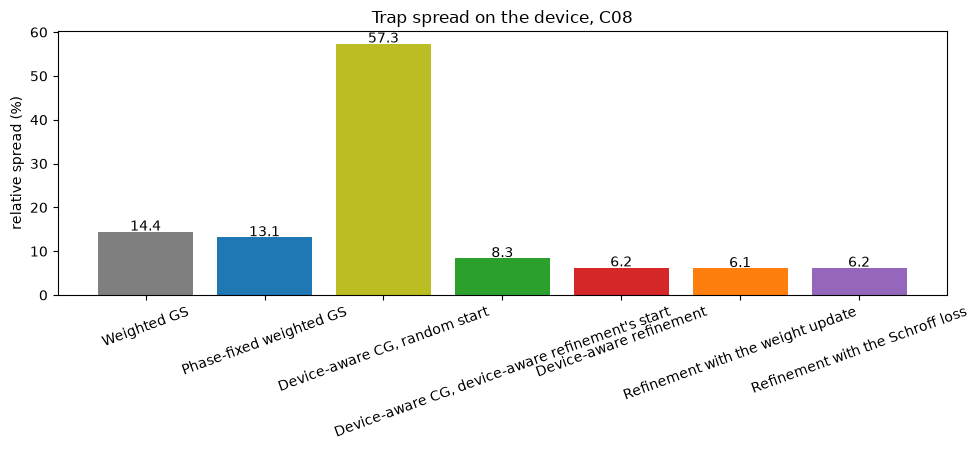

Weighted GS: 14.424 %
Phase-fixed weighted GS: 13.132 %
Device-aware CG, random start: 57.314 %
Device-aware CG, device-aware refinement's start: 8.349 %
Device-aware refinement: 6.240 %
Refinement with the weight update: 6.086 %
Refinement with the Schroff loss: 6.190 %


In [10]:
# the spread of the traps on the device: mean of two seeds for phase-fixed weighted GS and device-aware refinement, the
# first seed for weighted GS and device-aware CG
fig, ax = plt.subplots(figsize=(10, 4.6))
bars = {
    "Weighted GS": on_device(ideal_runs["Weighted GS"].phi, setup, traps, device)[2],
    "Phase-fixed weighted GS": m07_numbers[:, 2].mean(),
    "Device-aware CG, random start": cg_cold[2],
    "Device-aware CG, device-aware refinement's start": cg_numbers[2],
    "Device-aware refinement": b1_numbers[:, 2].mean(),
    "Refinement with the weight update": variant_numbers["with the weight update"][:2, 2].mean(),
    "Refinement with the Schroff loss": variant_numbers["normalized-error loss (Schroff et al.)"][:2, 2].mean(),
}
ax.tick_params(axis="x", labelrotation=20)
ax.bar(list(bars), list(bars.values()), color=["C7", "C0", "C8", "C2", "C3", "C1", "C4"])
for k, value in enumerate(bars.values()):
    ax.text(k, value + 0.3, f"{value:.1f}", ha="center")
ax.set_ylabel("relative spread (%)")
ax.set_title("Trap spread on the device, C08")
fig.tight_layout()
plt.show()
for name, value in bars.items():
    print(f"{name}: {value:.3f} %")

Of the methods started from a weighted Gerchberg-Saxton phase, the spread falls with how much of the device the method knows. Weighted GS, which knows none of it, has a spread of 14.4 percent and phase-fixed weighted GS, which converges on the ideal model, 13.1 percent on the mean of two seeds; both judged themselves on the ideal model at 1.262 and 0.005 percent, and a hundred iterations did not change a digit of phase-fixed weighted GS's result on the device. Device-aware CG, the conjugate gradient through the crosstalk operator, depends on its start: from its own random start 12 iterations leave it at 57.3 percent, an unconverged run, and from the start the refinement uses, 12 iterations of weighted GS, the same 12 gradient steps bring it to 8.3 percent on the first seed, and 40 steps leave it at 8.5. The refinement, which takes its steps through the device model after that start, ends at 6.2 percent on the mean of two seeds, and the two variants end at 6.1 (with the weight update) and 6.2 percent (with the Schroff loss), the same height as the default to the precision of the figure; the printout under it lists the values. The figure does not show the efficiency each method pays, which the table above prints.

The second figure has two panels. On the left, the ratio of the spread of phase-fixed weighted GS to that of device-aware refinement against the crosstalk width, from no crosstalk to the strongest. On the right, the efficiency of both.

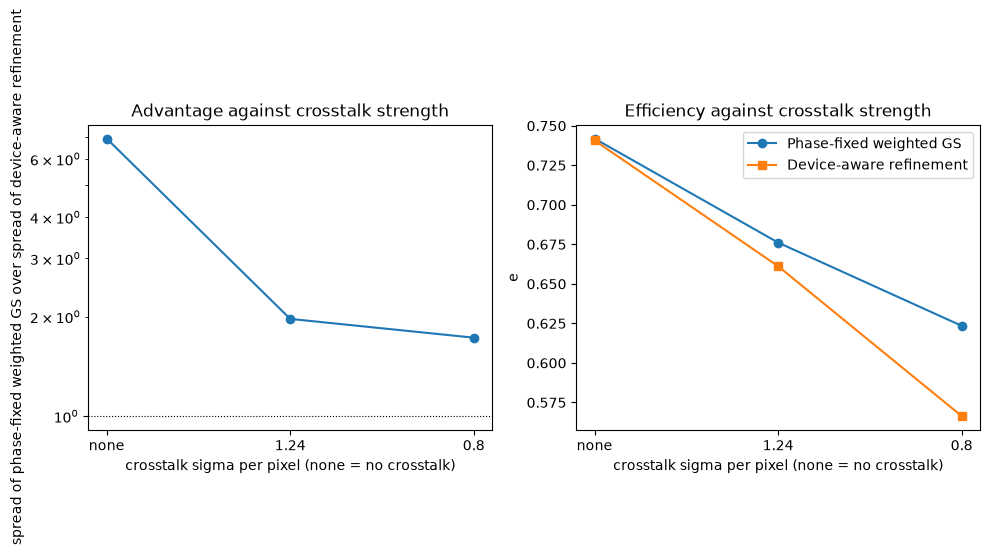

In [11]:
# the ratio of the two spreads against the crosstalk strength, and the efficiency each method keeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels = list(rows)
ax1.semilogy(labels, [rows[k][0][2] / rows[k][1][2] for k in labels], "o-")
ax1.axhline(1.0, color="k", lw=0.8, ls=":")
ax1.set_xlabel("crosstalk sigma per pixel (none = no crosstalk)")
ax1.set_ylabel("spread of phase-fixed weighted GS over spread of device-aware refinement")
ax1.set_title("Advantage against crosstalk strength")
ax2.plot(labels, [rows[k][0][0] for k in labels], "o-", label="Phase-fixed weighted GS")
ax2.plot(labels, [rows[k][1][0] for k in labels], "s-", label="Device-aware refinement")
ax2.set_xlabel("crosstalk sigma per pixel (none = no crosstalk)")
ax2.set_ylabel("e")
ax2.set_title("Efficiency against crosstalk strength")
ax2.legend()
fig.tight_layout()
plt.show()

The advantage is not a crosstalk effect alone. Without any crosstalk, with only 4 bits, a fill factor of 0.85 and flicker, phase-fixed weighted GS has a spread of 3.953 percent and the refinement 0.572, a ratio of 6.91, because the refinement sees the quantizer and the aperture too. As crosstalk grows both get worse and the ratio falls: 1.97 at the case's width of 1.24, and 1.73 at 0.8, where the refinement returns its third iterate with a spread of 14.215 percent against 24.540. The right panel shows the price. Without crosstalk the two efficiencies differ by 0.0011 (0.7407 against 0.7418); at 1.24 the refinement has 0.6612 against 0.6761, and at 0.8 it has 0.5664 against 0.6235, a ratio of 0.908, close to the floor of 0.9 of the warm start's efficiency that the safeguard enforces: with strong crosstalk the uniformity the refinement buys costs about a tenth of the light. The sweep uses one seed per point and one fixed number of steps, and it says nothing about devices with a different bit depth.

### Use it on your own data

The proposed method takes what a developer can measure or read from a datasheet: the number of phase bits, the crosstalk width and sharpness of the liquid crystal, the fill factor and the flicker. They enter through one object, `Device`, whose fields are the ones the record of contract 1 carries in its `device` block (`bit_depth`, `crosstalk` as the pair $(\sigma, q)$, `fill_factor`, `flicker_rad`); a `None` crosstalk turns that stage off. The cell below writes a device that is not the one of C08, 6 bits with a milder crosstalk of width 1.5 and fill 0.9, and an array that is not C08 either, 16 traps on a ring of 20 um from the `ring` helper. It runs phase-fixed weighted GS and device-aware refinement from the same seed, reads both on the device with the `on_device` function of this notebook (the mean of four flicker draws), and prints the spread that phase-fixed weighted GS reports about itself, the one it believes, next to the spread the device shows. The call of device-aware refinement is the one of the evidence section: `b1_device_wgs.run(setup, target, device=..., budget=Budget(4), rng=...)`, where the budget counts outer iterations of three conjugate-gradient steps. The last line of the cell runs the same call with `weights=True`.

In [12]:
# a device of your own: datasheet or calibration values, written as the Device the engine takes
mine_device = Device(bit_depth=6, crosstalk=(1.5, 1.8), fill_factor=0.9, flicker_rad=0.03)
mine_traps = ring(16, 20.0)
my_target = Target.from_traps(mine_traps)
print(f"{len(mine_traps)} traps on a ring of 20 um, device: {mine_device.bit_depth} bits, "
      f"crosstalk {mine_device.crosstalk}")
my_m07 = m07_phase_fixed_wgs.run(setup, my_target, budget=budget, rng=Rng(seeds[0]))
my_b1 = b1_device_wgs.run(setup, my_target, device=mine_device, budget=Budget(4), rng=Rng(seeds[0]))
my_w = b1_device_wgs.run(setup, my_target, device=mine_device, budget=Budget(4), rng=Rng(seeds[0]), weights=True)
my_read = {"Phase-fixed weighted GS": on_device(my_m07.phi, setup, mine_traps, mine_device),
           "Device-aware refinement": on_device(my_b1.phi, setup, mine_traps, mine_device)}
self_judged = my_m07.history[-1]["rel_std"]
print(f"Phase-fixed weighted GS judges itself at sigma = {self_judged:.3f} %")
for name, row in my_read.items():
    print(f"{name} on the device: e = {row[0]:.4f}, u = {row[1]:.4f}, sigma = {row[2]:.3f} %")
print(f"rho = {my_read['Phase-fixed weighted GS'][2] / my_read['Device-aware refinement'][2]:.2f}")
my_w_row = on_device(my_w.phi, setup, mine_traps, mine_device)
print(f"with the weight update on: e = {my_w_row[0]:.4f}, u = {my_w_row[1]:.4f}, sigma = {my_w_row[2]:.4f}")

16 traps on a ring of 20 um, device: 6 bits, crosstalk (1.5, 1.8)
Phase-fixed weighted GS judges itself at sigma = 0.000 %
Phase-fixed weighted GS on the device: e = 0.5573, u = 0.8144, sigma = 13.154 %
Device-aware refinement on the device: e = 0.5544, u = 0.9809, sigma = 0.945 %
rho = 13.92
with the weight update on: e = 0.5525, u = 0.9870, sigma = 0.7157


Phase-fixed weighted GS judges its own hologram at a spread of 0.000 percent on the ideal model, and the device shows 13.154 percent, with an efficiency of 0.5573 and a uniformity of 0.8144. The refinement on the same device gets 0.945 percent, a uniformity of 0.9809 and an efficiency of 0.5544, so the ratio $\rho$ of the two spreads is 13.92 and the cost in efficiency is half a percent (0.5544 against 0.5573). The ratio is larger than the 2.1 of C08, for a reason the crosstalk sweep predicts: with the milder crosstalk of 1.5 the blur is weaker, the gradient steps can undo most of it, and the 16 traps of a symmetric ring leave the loop little to fight. The last line of the printout runs the same call with the weight update on: it gives 0.716 percent, lower than the default's 0.945, where on C08 it changed nothing and on the product's acceptance task it makes the spread worse. The ratio is therefore not a property of the method but of the pair of the device and the array, and a claim of the size of the notebook's, a factor of about two, must be re-measured for each device, with and without the weight update. The figure draws the three numbers that matter: what the ideal-model method believes, what the device shows of it, and what the refinement recovers.

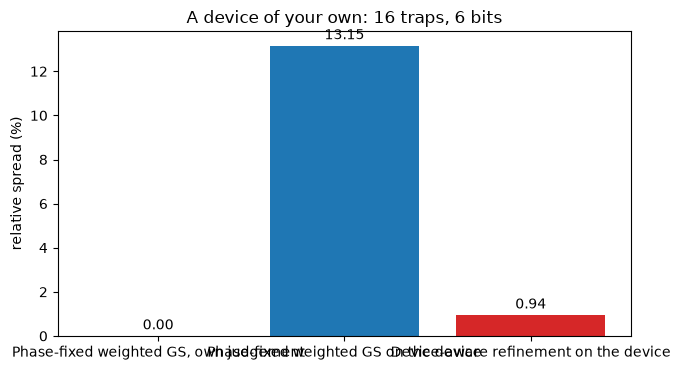

In [13]:
# what the method believes against what the device shows, and what device-aware refinement recovers
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = ["Phase-fixed weighted GS, own judgement", "Phase-fixed weighted GS on the device",
          "Device-aware refinement on the device"]
values = [self_judged, my_read["Phase-fixed weighted GS"][2], my_read["Device-aware refinement"][2]]
ax.bar(labels, values, color=["C7", "C0", "C3"])
for k, value in enumerate(values):
    ax.text(k, value + 0.3, f"{value:.2f}", ha="center")
ax.set_ylabel("relative spread (%)")
ax.set_title("A device of your own: 16 traps, 6 bits")
fig.tight_layout()
plt.show()

The first bar is zero because the method iterates until the ideal model is perfectly uniform on this symmetric array, the second is the same hologram on the device, and the third is device-aware refinement's: a method that is judged only by its own history reports a perfect hologram that the device shows at 13 percent. Four checks for a device of your own, in order. First, that the fields of `Device` come from a measurement, since a guessed crosstalk width changes the ratio from near 1 to large, as the sweep above showed. Second, that the hologram is read on the device and not on the ideal model, with several draws of the flicker. Third, that the efficiency cost of device-aware refinement is quoted next to its gain, here half a percent. Fourth, that the result is repeated on more than one seed and one array before it is claimed, which this section does not do: it shows the call and the reading on one array, and the claim of the notebook rests on the eight seeds against phase-fixed weighted GS, the two seeds against device-aware CG and the sweep of the evidence section. The limits are the ones named there: device-aware refinement is for point traps in the focal plane, it needs the device model to be right, and at the strongest crosstalk of the sweep it keeps a ratio of 1.73 but gives up about a tenth of the light.

## Results

**Answer:** Yes against both baselines on this device, and the gain comes from the device model in the steps, not from the weight update or from the loss. On the device of C08 the ideal-model methods are wrong about themselves: phase-fixed weighted Gerchberg-Saxton judges its own hologram at a spread of 0.005 percent and the device shows 13.349 percent, and 100 iterations instead of 30 change nothing. The device-aware conjugate-gradient refinement, with 4 outer iterations of 3 conjugate-gradient steps after 12 iterations of weighted GS, reaches 6.240 percent on average over two seeds (5.696 to 6.785), against 13.132 percent for phase-fixed weighted GS (12.915 to 13.349), a factor of 2.1 at 0.978 of its efficiency; the uniformity is 0.8637 against 0.7086. Over eight seeds the ratio of the spreads has a median of 2.10, a range from 1.72 to 2.41 and a bootstrap 95 percent interval of the median from 1.78 to 2.25, with the refinement at least twice as uniform on 4 of the 8 seeds and at a median of 0.983 of phase-fixed weighted GS's efficiency. The strongest baseline, the conjugate gradient through the crosstalk operator, given the same start and the same 12 gradient steps, reaches 8.349 percent on the first seed and 7.743 on the second, with efficiencies of 0.6712 and 0.6768, where the refinement has 6.785 and 5.696 percent: its spread is lower by a factor of 1.23 and 1.36, at 0.985 and 0.984 of device-aware CG's efficiency. Forty iterations of device-aware CG from the first start leave it at 8.508 percent, no lower than at 12, so more iterations do not close the gap. The two variants do not move the result on this device: with the weight update the median spread over eight seeds is 6.316 percent against 6.238 for the default (per-seed ratios 0.92 to 1.06), and with the normalized-error loss of Schroff et al. it is 6.222 percent (ratios 0.99 to 1.03, the same efficiency at the median), so the closest published loss is not worse than the product's here. The advantage depends on the device: 6.91 times with no crosstalk, 1.97 at the crosstalk of the case and 1.73 at a width of 0.8, where the refinement keeps 0.908 of phase-fixed weighted GS's efficiency (0.5664 against 0.6235). On a 16-trap ring with a 6-bit device the ratio is 13.92, and the weight update, which changed nothing on C08, lowers the spread there from 0.945 to 0.716 percent.

## Summary

A hologram computed for an ideal SLM is wrong about itself on a device with 4 bits and crosstalk, by a factor of 11 for weighted Gerchberg-Saxton and by orders of magnitude for the phase-fixed variant, and more iterations do not repair it. Taking conjugate-gradient steps through the device model after a weighted start, as the device-aware refinement does, lowers the spread of phase-fixed weighted Gerchberg-Saxton by a median factor of 2.10 on eight seeds at a cost of about 2 percent of the efficiency, and beats the device-aware conjugate gradient from the same start and with the same number of steps by a smaller margin (1.23 and 1.36). Neither the weight update nor the choice between the product's loss and the normalized-error loss of Schroff et al. changes the spread on this device; the weight update does change it on other tasks (it lowers the spread of a 16-trap ring, and it makes the spread of the product's acceptance task about 7 times worse), so the default is a measurement to repeat for each device and array. With strong crosstalk the gain stays at 1.73 but costs about a tenth of the light. What is not tested here is a conjugate gradient run beyond 40 iterations, a different bit depth or fill factor, flicker in the loop, more than two seeds for the comparison with the conjugate gradient, and the larger lattices of the product's benchmark, where the refinement meets both thresholds of the claim (a factor of 2 at 0.9 of the efficiency) on four of six geometries and fails them on the 10 x 10 lattice and on the quasi-periodic set (the device-aware manuscript's data, not recomputed here).

## References

- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.
- Kim, Keesling, Omran, Levine, Bernien, Greiner, Lukin and Englund, "Large-scale uniform optical focus array generation with a phase spatial light modulator", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.

- Nogrette et al., "Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries", Physical Review X 4, 021034 (2014), https://arxiv.org/abs/1402.5329.
- Persson, Engstrom and Goksor, "Reducing the effect of pixel crosstalk in phase only spatial light modulators", Optics Express 20, 22334 (2012), https://doi.org/10.1364/OE.20.022334.
